In [1]:
%run sem2.py

In [2]:
import pandas as pd
import numpy as np
import torch
from torch.utils.data import TensorDataset, DataLoader
from torch import nn
from engression.loss_func import energy_loss, energy_loss_two_sample
import matplotlib.pyplot as plt
import time

In [3]:
df = pd.read_csv('PoliticalDemocracy.csv')
var_names = df.columns.values.tolist()
dataset = torch.tensor(df.to_numpy()).to(dtype = torch.float32)
batch_size = 25
dataloader = DataLoader(TensorDataset(dataset), batch_size = batch_size, shuffle = True)
print(var_names)

['y1', 'y2', 'y3', 'y4', 'y5', 'y6', 'y7', 'y8', 'x1', 'x2', 'x3']


In [4]:
# Linear factor model
model_formula = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3; ind60 ~ norm; ex1 ~ norm; ex2 ~ norm; ex3 ~ norm"
model = sem2(model_formula)
observed_var = ["x1", "x2", "x3"]
x = dataset[:, [var_names.index(var) for var in observed_var]]
observed_index = [list(model.static_order()).index(var) for var in observed_var]

In [5]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model.train()
for i in range(2000):
    optimizer.zero_grad()
    sample1 = model(x.size(0))[:, observed_index]
    sample2 = model(x.size(0))[:, observed_index]
    loss, s1, s2 = energy_loss_two_sample(x, sample1, sample2)
    loss.backward()
    optimizer.step()
    if i == 0 or (i + 1) % 100 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')

Iter 1 | loss: 7.5814, s1: 8.2681, s2: 1.3734
Iter 100 | loss: 5.1059, s1: 7.1087, s2: 4.0056
Iter 200 | loss: 3.4378, s1: 6.2371, s2: 5.5987
Iter 300 | loss: 2.3763, s1: 5.5939, s2: 6.4352
Iter 400 | loss: 2.3945, s1: 5.2828, s2: 5.7765
Iter 500 | loss: 1.6519, s1: 4.2826, s2: 5.2614
Iter 600 | loss: 1.5834, s1: 3.5084, s2: 3.8500
Iter 700 | loss: 1.1650, s1: 2.7057, s2: 3.0814
Iter 800 | loss: 1.2127, s1: 2.6479, s2: 2.8704
Iter 900 | loss: 1.3035, s1: 2.6103, s2: 2.6136
Iter 1000 | loss: 1.2326, s1: 2.5692, s2: 2.6732
Iter 1100 | loss: 1.1208, s1: 2.6296, s2: 3.0175
Iter 1200 | loss: 1.2435, s1: 2.5993, s2: 2.7116
Iter 1300 | loss: 1.5252, s1: 2.9711, s2: 2.8919
Iter 1400 | loss: 1.2497, s1: 2.5769, s2: 2.6543
Iter 1500 | loss: 1.1796, s1: 2.6522, s2: 2.9453
Iter 1600 | loss: 1.0903, s1: 2.5104, s2: 2.8400
Iter 1700 | loss: 1.5097, s1: 2.9466, s2: 2.8738
Iter 1800 | loss: 1.3534, s1: 2.5973, s2: 2.4877
Iter 1900 | loss: 1.2371, s1: 2.6022, s2: 2.7302
Iter 2000 | loss: 1.4449, s1: 2.

In [6]:
beta = [model.layer[node].weight[0][0].squeeze().detach().numpy().tolist() for node in observed_var]
[beta[i] / beta[0] for i in range(3)]

[1.0, 2.0182955436414334, 1.9177564179610112]

In [7]:
# Linear factor model (same as lavaan package example)
# Loss function: log-likelihood
formula_epsx = "ex1 ~ norm; ex2 ~ norm; ex3 ~ norm;" 
formula_epsy = "ey1 ~ norm; ey2 ~ norm; ey3 ~ norm; ey4 ~ norm; ey5 ~ norm; ey6 ~ norm; ey7 ~ norm; ey8 ~ norm;"
formula_epsdem = "edem60 ~ norm; edem65 ~ norm;"
formula_epscov = "e15 ~ norm; e24 ~ norm; e26 ~ norm; e37 ~ norm; e48 ~ norm; e68 ~ norm;"
formula_end = "ind60 ~ norm; dem60 <- ind60 + edem60; dem65 <- ind60 + dem60 + edem65;"
formula_x = "x1 <- ind60 + ex1; x2 <- ind60 + ex2; x3 <- ind60 + ex3;"
formula_y1 = "y1 <- dem60 + ey1 + e15; y2 <- dem60 + ey2 + e24 + e26; y3 <- dem60 + ey3 + e37; y4 <- dem60 + ey4 + e24 + e48;"
formula_y2 = "y5 <- dem65 + ey5 + e15; y6 <- dem65 + ey6 + e26 + e68; y7 <- dem65 + ey7 + e37; y8 <- dem65 + ey8 + e48 + e68"
formula2 = formula_epsx + formula_epsy + formula_epsdem + formula_epscov + formula_end + formula_x + formula_y1 + formula_y2
lavaan_coefs = [1.483, 0.572, 0.837]

In [8]:
observed_var = var_names
x = dataset[:, [var_names.index(var) for var in observed_var]]
sd = torch.std(x, dim = 0)
print(sd)
x_normalized = torch.zeros_like(x)
for i in range(x.size(1)):
    x_normalized[:,i] = x[:,i] / sd[i]
sample_cov = torch.cov(torch.t(x))

tensor([2.6227, 3.9471, 3.2809, 3.3495, 2.6126, 3.3727, 3.2862, 3.2456, 0.7329,
        1.5107, 1.4057])


In [9]:
# Maximum likelihood (use sample from model to estimate variance)
model2 = sem2(formula2)
observed_index = [list(model2.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model2.parameters(), lr=5e-2)
model2.train()
niter = 1000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    model_sample = model2(x.size(0) * 10)[:, observed_index]
    model_cov = torch.cov(torch.t(model_sample))
    loss = torch.log(torch.det(model_cov)) + torch.trace(sample_cov @ torch.inverse(model_cov))
    # loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model2.layer["x1"].weight[0][0]
    dem60_scale = model2.layer["y1"].weight[0][0]
    dem65_scale = model2.layer["y5"].weight[0][0]
    coefs[i,:] = torch.tensor([model2.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model2.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model2.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 1014.4991, s1: 2.8083, s2: 2.7268
[-0.0406259   0.01718221 -0.28333193]
Iter 1000 | loss: 21.3961, s1: 2.8083, s2: 2.7268
[1.39322102 0.45622337 0.81164867]


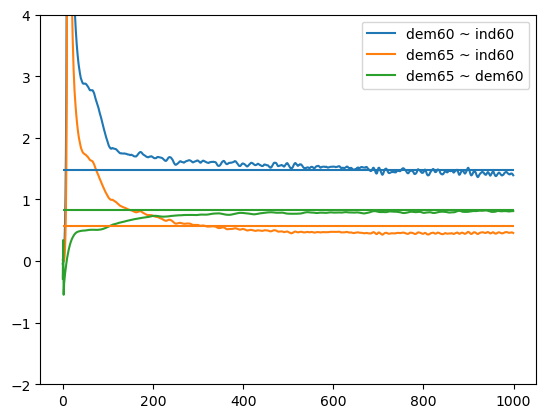

In [10]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [11]:
# Energy loss minimization (100 * data size to estimate loss, normalize x first)
model3 = sem2(formula2, device = "cpu")
x_normalized = x_normalized.to("cpu")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model3.parameters(), lr=1e-2)
model3.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model3(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model3.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model3.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model3.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model3.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model3.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model3.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 8.8496, s1: 10.2117, s2: 2.7242
[-1.15827489  0.29847449  0.23537645]
Iter 1000 | loss: 2.1724, s1: 4.4286, s2: 4.5123
[1.6921922  0.69327843 0.84873736]
Iter 2000 | loss: 2.1932, s1: 4.4490, s2: 4.5116
[1.7297554  0.77080768 0.8098563 ]
Iter 3000 | loss: 2.1846, s1: 4.4244, s2: 4.4796
[1.77567124 0.67784697 0.82323384]


In [12]:
# Run time of one iteration
start = time.time()
sample = model3(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

0.040370941162109375


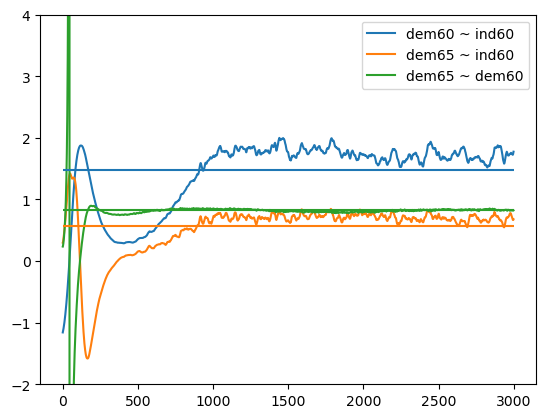

In [13]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()

In [ ]:
# Energy loss minimization on GPU
model4 = sem2(formula2, device = "mps")
x_normalized = x_normalized.to("mps")
observed_index = [list(model3.static_order()).index(var) for var in observed_var]
optimizer = torch.optim.Adam(model4.parameters(), lr=1e-2)
model4.train()
niter = 3000
coefs = np.zeros([niter, 3])
for i in range(niter):
    optimizer.zero_grad()
    sample = model4(x.size(0) * 100)[:, observed_index]
    loss, s1, s2 = energy_loss(x_normalized, sample)
    loss.backward()
    optimizer.step()
    ind60_scale = model4.layer["x1"].weight[0][0] * sd[var_names.index("x1")]
    dem60_scale = model4.layer["y1"].weight[0][0] * sd[var_names.index("y1")]
    dem65_scale = model4.layer["y5"].weight[0][0] * sd[var_names.index("y5")]
    coefs[i,:] = torch.tensor([model4.layer["dem60"].weight[0][0] / ind60_scale * dem60_scale,
                               model4.layer["dem65"].weight[0][0] / ind60_scale * dem65_scale,
                               model4.layer["dem65"].weight[0][1] / dem60_scale * dem65_scale]).numpy()
    if i == 0 or (i + 1) % 1000 == 0:
        print(f'Iter {i + 1} | loss: {loss.item():.4f}, s1: {s1.item():.4f}, s2: {s2.item():.4f}')
        print(coefs[i, :])

Iter 1 | loss: 7.8906, s1: 9.0871, s2: 2.3929
[-1.68938506  0.38237914 -0.32575399]
Iter 1000 | loss: 2.2120, s1: 4.4475, s2: 4.4709
[2.0733974  0.91790563 0.81329709]
Iter 2000 | loss: 2.2060, s1: 4.4415, s2: 4.4710
[1.83743346 0.77597338 0.81645769]


In [ ]:
# Run time of one iteration
start = time.time()
sample = model4(x.size(0) * 100)[:, observed_index]
loss, s1, s2 = energy_loss(x_normalized, sample)
loss.backward()
optimizer.step()
end = time.time()
print(end - start)

In [ ]:
plt.plot(range(niter), coefs[:,0], label = "dem60 ~ ind60")
plt.plot(range(niter), coefs[:,1], label = "dem65 ~ ind60")
plt.plot(range(niter), coefs[:,2], label = "dem65 ~ dem60")
plt.hlines(lavaan_coefs, xmin = 0, xmax = niter, colors = ["C0", "C1", "C2"])
plt.ylim(-2, 4)
plt.legend()